# So sánh tuning A12, B27 và C30

Notebook này chỉ đọc kết quả đã lưu, không huấn luyện lại. Dừng ngay nếu khác protocol, cohort, fold, danh sách ứng viên hoặc thứ tự OOF. Không chấm validation/test.

## 1. Đọc và xác minh kết quả

Đối chiếu hash của cả ba protocol, số mẫu, mốc lịch và ngân sách. Điểm của các mô hình được chọn được tính lại từ OOF để kiểm tra JSON.

In [1]:
from pathlib import Path
import sys
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'data/preprocessed/hourly_unfilled.csv').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
import pandas as pd
from IPython.display import Markdown, display
from src import tuning_cv as cv
comparison = cv.load_comparison(project_root)
p = comparison['protocol']
display(pd.DataFrame([dict(config=c, protocol_hash=comparison['records'][c]['protocol_hash'],
                           n=p['n_oof'], n_cohort=p['n_cohort'], candidates=p['n_candidates'],
                           n_models=len(p['model_names']), matches=True) for c in cv.CONFIGS]))
display(pd.DataFrame(p['folds']))

,config,protocol_hash,n,n_cohort,candidates,n_models,matches
0,A12,6042efc8e56db7968fddaa33ee9d8b43d53c817fb778b1...,16875,22503,6,5,True
1,B27,6042efc8e56db7968fddaa33ee9d8b43d53c817fb778b1...,16875,22503,6,5,True
2,C30,6042efc8e56db7968fddaa33ee9d8b43d53c817fb778b1...,16875,22503,6,5,True


,fold,fit_start,fit_end,score_start,score_end,n_fit,n,fit_calendar_hours,score_calendar_hours,fit_hash,score_hash
0,1,2012-10-09 09:00:00,2013-08-05 19:00:00,2013-08-05 20:00:00,2015-07-12 06:00:00,5628,5625,7211.0,16931.0,907f339dcf7453df3f5e70f83fd477f72bdfd531e01eae...,3e445aa0bc2af81e32b3d2126a6f9e34073d17a6872bc0...
1,2,2012-10-09 09:00:00,2015-07-12 06:00:00,2015-07-12 07:00:00,2016-09-07 17:00:00,11253,5625,24142.0,10163.0,0a956b96e0a294dfd75ca7d8b49aa36b9e6cbffd755794...,a1d7f7f4f11fc1da3571b8dfdba463987d69e3ef1adee3...
2,3,2012-10-09 09:00:00,2016-09-07 17:00:00,2016-09-07 18:00:00,2017-05-10 04:00:00,16878,5625,34305.0,5867.0,a64f6fc3241daadbcf0a479c22878e11e10c69bfa3c4e2...,4117d3a132e44ecc9c0f8eea01e43dc911e7758ea92dc3...


## 2. Bảng điểm sau tuning

Báo trung bình và SD của MAE, RMSE, R² theo fold. Hai baseline chỉ hiển thị một lần ở nhóm common vì chúng có cùng dự đoán trong cả ba cấu hình.

In [2]:
display(comparison['summary'])
output = project_root / 'notebooks/tuning/outputs'
comparison['summary'].to_csv(output / 'comparison_summary.csv', index=False)
# Bảng kiểm toán từ đúng các ứng viên đã fit, không chỉ lưới khai báo.
audit_rows = []
for config, record in comparison['records'].items():
    for model in record['results']:
        for trial in model['candidates']:
            audit_rows.append(dict(config=config, model=model['model'], candidate=trial['candidate'],
                parameters_json=__import__('json').dumps(trial['parameters'], sort_keys=True),
                MAE_CV=trial['MAE_mean'], RMSE_CV=trial['RMSE_mean'],
                n_folds=len(trial['folds']), n=sum(f['n'] for f in trial['folds'])))
audit = pd.DataFrame(audit_rows)
assert audit.groupby(['config', 'model']).size().eq(p['n_candidates']).all()
audit.to_csv(output / 'cv_candidates.csv', index=False)
display(audit.loc[audit.model.eq('Random Forest')])


,config,model,n,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
0,A12,Ridge,16875,317.033621,33.288909,487.929444,58.752916,0.937639,0.015329
1,A12,Random Forest,16875,288.182262,20.674355,463.379493,39.654253,0.944023,0.009874
2,A12,Gradient Boosting,16875,300.498659,34.274467,470.428977,54.829987,0.942034,0.014175
3,A12,MLP,16875,303.579039,39.273389,475.703933,65.207970,0.940525,0.016969
4,A12,XGBoost,16875,290.449713,34.487217,464.275801,47.528842,0.943662,0.012119
5,B27,Ridge,16875,314.800957,33.377945,484.152216,61.610615,0.938535,0.015902
6,B27,Random Forest,16875,286.822741,29.236683,459.862372,57.962498,0.944530,0.014569
7,B27,Gradient Boosting,16875,312.711841,22.765098,482.708457,55.649967,0.939020,0.014299
8,B27,MLP,16875,356.427187,21.099708,539.066795,52.619348,0.924152,0.014938
9,B27,XGBoost,16875,296.102179,30.681304,474.541855,64.965461,0.940850,0.016449


,config,model,candidate,parameters_json,MAE_CV,RMSE_CV,n_folds,n
6,A12,Random Forest,1,"{""model__max_depth"": 8, ""model__max_features"":...",288.182262,463.379493,3,16875
7,A12,Random Forest,2,"{""model__max_depth"": 8, ""model__max_features"":...",297.782126,464.090087,3,16875
8,A12,Random Forest,3,"{""model__max_depth"": 12, ""model__max_features""...",289.519129,471.737653,3,16875
9,A12,Random Forest,4,"{""model__max_depth"": 16, ""model__max_features""...",296.785625,473.090799,3,16875
10,A12,Random Forest,5,"{""model__max_depth"": 16, ""model__max_features""...",288.542641,462.629754,3,16875
11,A12,Random Forest,6,"{""model__max_depth"": 20, ""model__max_features""...",295.008407,473.299402,3,16875
36,B27,Random Forest,1,"{""model__max_depth"": 8, ""model__max_features"":...",294.668811,474.613717,3,16875
37,B27,Random Forest,2,"{""model__max_depth"": 8, ""model__max_features"":...",300.605935,465.946538,3,16875
38,B27,Random Forest,3,"{""model__max_depth"": 12, ""model__max_features""...",291.694896,473.741426,3,16875
39,B27,Random Forest,4,"{""model__max_depth"": 16, ""model__max_features""...",296.394802,478.719793,3,16875


## 3. Chênh lệch theo từng fold

Delta = cấu hình sau − cấu hình trước. Delta MAE/RMSE âm nghĩa là lỗi giảm; delta R² dương nghĩa là chỉ số tăng. Đọc từng mô hình riêng, không giả định cùng cấu hình sẽ thắng với mọi mô hình.

In [3]:
deltas = cv.paired_fold_deltas(comparison)
display(deltas)
display(deltas.groupby(['model', 'comparison']).agg(delta_MAE=('delta_MAE', 'mean'),
         delta_RMSE=('delta_RMSE', 'mean'), delta_R2=('delta_R2', 'mean'),
         folds_lower_MAE=('delta_MAE', lambda s: int(s.lt(0).sum())), n=('n', 'sum')).reset_index())
deltas.to_csv(output / 'paired_fold_deltas.csv', index=False)

,model,comparison,fold,n,delta_MAE,delta_RMSE,delta_R2
0,Ridge,B27 - A12,1,5625,-0.214731,-2.668519,0.000648
1,Ridge,B27 - A12,2,5625,-1.339343,-1.337030,0.000385
2,Ridge,B27 - A12,3,5625,-5.143919,-7.326135,0.001656
3,Random Forest,B27 - A12,1,5625,-5.230907,-15.154479,0.003450
4,Random Forest,B27 - A12,2,5625,10.748160,18.710274,-0.005048
5,Random Forest,B27 - A12,3,5625,-9.595816,-14.107159,0.003119
6,Gradient Boosting,B27 - A12,1,5625,28.480442,27.342452,-0.006422
7,Gradient Boosting,B27 - A12,2,5625,2.747921,8.599502,-0.002417
8,Gradient Boosting,B27 - A12,3,5625,5.411184,0.896488,-0.000203
9,MLP,B27 - A12,1,5625,82.707344,82.451633,-0.020747


,model,comparison,delta_MAE,delta_RMSE,delta_R2,folds_lower_MAE,n
0,Gradient Boosting,B27 - A12,12.213183,12.279480,-0.003014,0,16875
1,Gradient Boosting,C30 - B27,-56.780983,-72.402124,0.017018,3,16875
2,MLP,B27 - A12,52.848149,63.362862,-0.016373,0,16875
3,MLP,C30 - B27,-79.313829,-120.890747,0.030271,3,16875
4,Random Forest,B27 - A12,-1.359521,-3.517121,0.000507,2,16875
5,Random Forest,C30 - B27,-55.783258,-78.502655,0.017470,3,16875
6,Ridge,B27 - A12,-2.232664,-3.777228,0.000896,3,16875
7,Ridge,C30 - B27,-52.836831,-66.728834,0.015958,3,16875
8,XGBoost,B27 - A12,5.652466,10.266054,-0.002812,1,16875
9,XGBoost,C30 - B27,-60.118649,-88.481815,0.020256,3,16875


## 4. Bất định của chênh lệch trên cùng giờ OOF

Bootstrap lấy lại các khối 7 ngày lịch trong từng fold, 2.000 lần, seed cố định. Giữ cả ngày không có mẫu dưới dạng tổng/n=0 để không nối giả các giờ qua khoảng trống; không nối khối qua biên fold. Gain = MAE trước − MAE sau, dương là phương án sau tốt hơn.

Khoảng tin cậy chứa 0 cho thấy chưa tách được chiều cải thiện trong phép bootstrap này. Đây là CI có điều kiện theo các tham số đã chọn bằng chính CV, chưa hiệu chỉnh thiên lệch do tìm kiếm. Chênh trung bình nhỏ so với SD giữa fold cần đọc thận trọng; SD không phải kiểm định có cặp.

In [4]:
bootstrap = cv.block_bootstrap_deltas(comparison)
bootstrap['reading'] = bootstrap.apply(lambda r: 'Chưa tách được chiều cải thiện'
    if r.CI95_low <= 0 <= r.CI95_high else 'CI có điều kiện không chứa 0; chưa phải kiểm định độc lập', axis=1)
display(bootstrap)
bootstrap.to_csv(output / 'paired_block_bootstrap.csv', index=False)

,model,comparison,MAE_gain,CI95_low,CI95_high,block_days,valid_replicates,n,reading
0,Ridge,B27 vs A12,2.232664,-0.386197,4.780050,7,2000,16875,Chưa tách được chiều cải thiện
1,Random Forest,B27 vs A12,1.359521,-3.858554,7.161198,7,2000,16875,Chưa tách được chiều cải thiện
2,Gradient Boosting,B27 vs A12,-12.213183,-20.315190,-5.353620,7,2000,16875,CI có điều kiện không chứa 0; chưa phải kiểm đ...
3,MLP,B27 vs A12,-52.848149,-61.866269,-44.491222,7,2000,16875,CI có điều kiện không chứa 0; chưa phải kiểm đ...
4,XGBoost,B27 vs A12,-5.652466,-13.521547,0.907341,7,2000,16875,Chưa tách được chiều cải thiện
5,Ridge,C30 vs B27,52.836831,42.064479,63.134765,7,2000,16875,CI có điều kiện không chứa 0; chưa phải kiểm đ...
6,Random Forest,C30 vs B27,55.783258,45.319511,66.081493,7,2000,16875,CI có điều kiện không chứa 0; chưa phải kiểm đ...
7,Gradient Boosting,C30 vs B27,56.780983,44.199086,68.695558,7,2000,16875,CI có điều kiện không chứa 0; chưa phải kiểm đ...
8,MLP,C30 vs B27,79.313829,65.528260,91.493797,7,2000,16875,CI có điều kiện không chứa 0; chưa phải kiểm đ...
9,XGBoost,C30 vs B27,60.118649,46.875359,72.928034,7,2000,16875,CI có điều kiện không chứa 0; chưa phải kiểm đ...


## 5. MAE theo mô hình và cấu hình

Đọc biểu đồ như sau: cột thấp hơn có MAE trung bình nhỏ hơn; thanh sai số là SD giữa ba fold, không phải CI của chênh lệch. Các phương án đều chấm đúng cùng tập giờ.

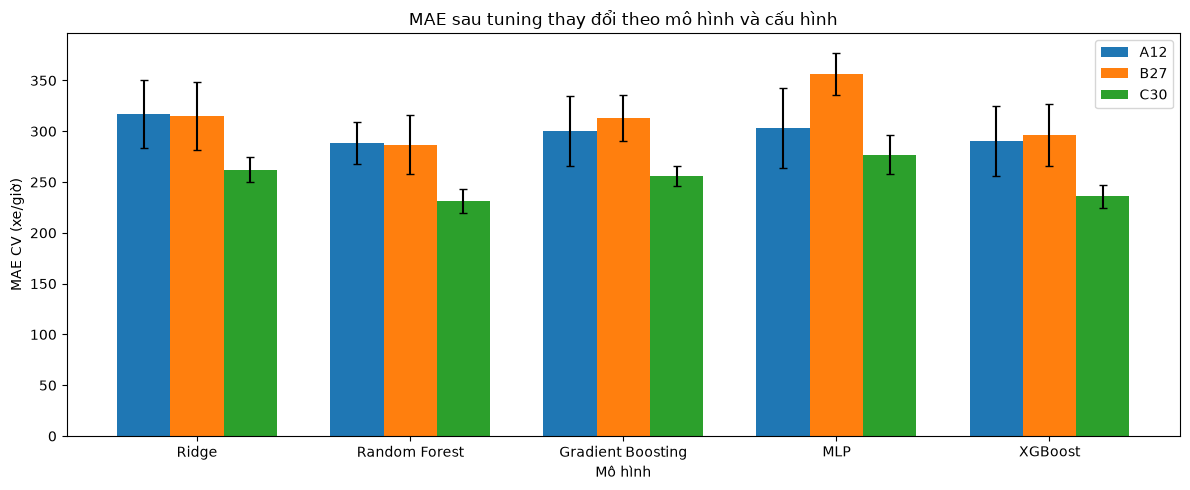

In [5]:
cv.plot_comparison(comparison)

## 6. Kết luận và bước tiếp theo

Kết luận được tính từ bảng, có đối chiếu RF cố định ở FE. Chọn ứng viên C30 để chuyển sang ensemble/validation; chưa sử dụng test và chưa tuyên bố mô hình cuối cùng.

In [6]:
text = cv.conclusion(comparison)
display(Markdown(text))
(output / 'comparison_summary.md').write_text(text + '\n', encoding='utf-8')

Thấp nhất toàn bảng: Random Forest / C30, MAE 231.039, RMSE 381.360 xe/giờ. Trong C30, chọn Random Forest theo MAE CV 231.039 xe/giờ để chuyển sang ensemble/validation; chưa phải mô hình cuối sau holdout. C30 vẫn là cấu hình của kết quả tốt nhất toàn bảng sau tuning. Riêng RF sau tuning, cấu hình tốt nhất là C30. RF C30 cố định ở FE: 247.926; RF C30 sau tuning: 231.039 xe/giờ. Ba fold là ít và phủ khoảng lịch khác nhau; ngân sách sáu ứng viên/mô hình còn nhỏ. SD mô tả biến động theo giai đoạn, không phải kiểm định chênh lệch. Bootstrap OOF dùng lại CV đã chọn tham số, nên CI chỉ mô tả bất định có điều kiện và chưa phải bằng chứng kiểm định độc lập. Chưa chấm validation/test.

684